# Fiche 1 — Que représente une ligne ? Doublons, valeurs manquantes, faux pays

| | |
|---|---|
| 🎯 **Objectif** | Savoir décrire un jeu de données avant de le transformer |
| ⏱️ **Durée** | 30 à 45 min |
| 🧰 **Prérequis** | Savoir lire un CSV avec `pd.read_csv` |
| 🔗 **Dans le projet** | Exercice partie 1, étapes 2 et 3 |

> **L'idée clé.** Avant tout calcul, il faut pouvoir compléter la phrase : « *dans ce fichier, une ligne = …* ».
> C'est ce qu'on appelle la **maille** (ou la granularité). Se tromper de maille, c'est additionner des choux
> et des carottes sans le savoir.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from edstats import viz
from edstats.io import load_tables

viz.apply_style()
pd.set_option("display.max_colwidth", 70)

tables = load_tables()
data, country = tables["Data"], tables["Country"]

## 1. Trouver la maille

**Méthode** : repérer les colonnes qui *identifient* une ligne (des codes, des noms…) et vérifier qu'aucune
combinaison ne se répète. Si c'est le cas, on a trouvé la **clé**.

In [2]:
data[["Country Code", "Indicator Code", "2010", "2011"]].head(4)

,Country Code,Indicator Code,2010,2011
0,ARB,UIS.NERA.2,NaN,NaN
1,ARB,UIS.NERA.2.F,NaN,NaN
2,ARB,UIS.NERA.2.GPI,NaN,NaN
3,ARB,UIS.NERA.2.M,NaN,NaN


In [3]:
# Hypothèse : une ligne = un (pays, indicateur). On la TESTE au lieu de la supposer.
print("Doublons sur (pays, indicateur) :", data.duplicated(subset=["Country Code", "Indicator Code"]).sum())
print("Doublons sur le pays seul        :", data.duplicated(subset=["Country Code"]).sum())

Doublons sur (pays, indicateur) : 0
Doublons sur le pays seul        : 886688


- 0 doublon sur (pays, indicateur) : l'hypothèse tient, **une ligne = un pays × un indicateur**.
- Des centaines de milliers de doublons sur le pays seul : le pays seul n'est **pas** la clé.

Les années sont ici des **colonnes** : c'est le format **large**. Le même contenu peut s'écrire en format
**long**, avec une ligne par (pays, indicateur, année) :

In [4]:
extrait = data.loc[data["Indicator Code"] == "SP.POP.TOTL", ["Country Code", "Indicator Code", "2010", "2011"]].head(2)
display(extrait)  # large : 2 lignes, une colonne par année
extrait.melt(id_vars=["Country Code", "Indicator Code"], var_name="annee", value_name="valeur")  # long : 4 lignes

,Country Code,Indicator Code,2010,2011
2533,ARB,SP.POP.TOTL,3.477370e+08,3.551370e+08
6198,EAS,SP.POP.TOTL,2.205615e+09,2.220358e+09


,Country Code,Indicator Code,annee,valeur
0,ARB,SP.POP.TOTL,2010,3.477370e+08
1,EAS,SP.POP.TOTL,2010,2.205615e+09
2,ARB,SP.POP.TOTL,2011,3.551370e+08
3,EAS,SP.POP.TOTL,2011,2.220358e+09


| Format | Pratique pour… | Outil pandas |
|---|---|---|
| **Large** (une colonne par année) | lire, comparer des années côte à côte | `pivot_table` pour y aller |
| **Long** (une ligne par année) | calculer par groupe (`groupby`), tracer avec seaborn | `melt` pour y aller |

## 2. Doublons : deux sortes de doublons

1. **Doublon exact** : toute la ligne est identique, d'où `df.duplicated()`.
2. **Doublon de clé** : deux lignes pour le même (pays, indicateur), mais avec des valeurs différentes : laquelle
   croire ? Il se détecte avec `df.duplicated(subset=clé)`.

`drop_duplicates()` ne règle que le premier cas. Le second demande une **décision** (garder la plus récente ?
faire la moyenne ?), qui doit être documentée.

In [5]:
# Démonstration sur un mini-tableau fabriqué
mini = pd.DataFrame({"pays": ["FRA", "FRA", "FRA"], "indicateur": ["POP", "POP", "POP"], "valeur": [65, 65, 66]})
print("doublons exacts       :", mini.duplicated().sum())
print("doublons de clé       :", mini.duplicated(subset=["pays", "indicateur"]).sum())
mini.drop_duplicates()  # il reste 2 lignes pour FRA/POP : le doublon de clé est toujours là !

doublons exacts       : 1
doublons de clé       : 2


,pays,indicateur,valeur
0,FRA,POP,65
2,FRA,POP,66


## 3. Valeurs manquantes

Deux questions à se poser :
1. **Combien ?** `df.isna().mean()` donne la proportion de vides par colonne (la moyenne de True/False est une
   proportion).
2. **Où ?** Les vides sont-ils dispersés au hasard, ou concentrés sur certaines colonnes ou certaines lignes ?

In [6]:
taux_vides = (data.isna().mean() * 100).round(1)
taux_vides[["1970", "1990", "2000", "2010", "2014", "2016", "2017", "2030"]].to_frame("% vides").T

,1970,1990,2000,2010,2014,2016,2017,2030
% vides,91.8,86.0,80.1,72.7,87.2,98.1,100.0,94.2


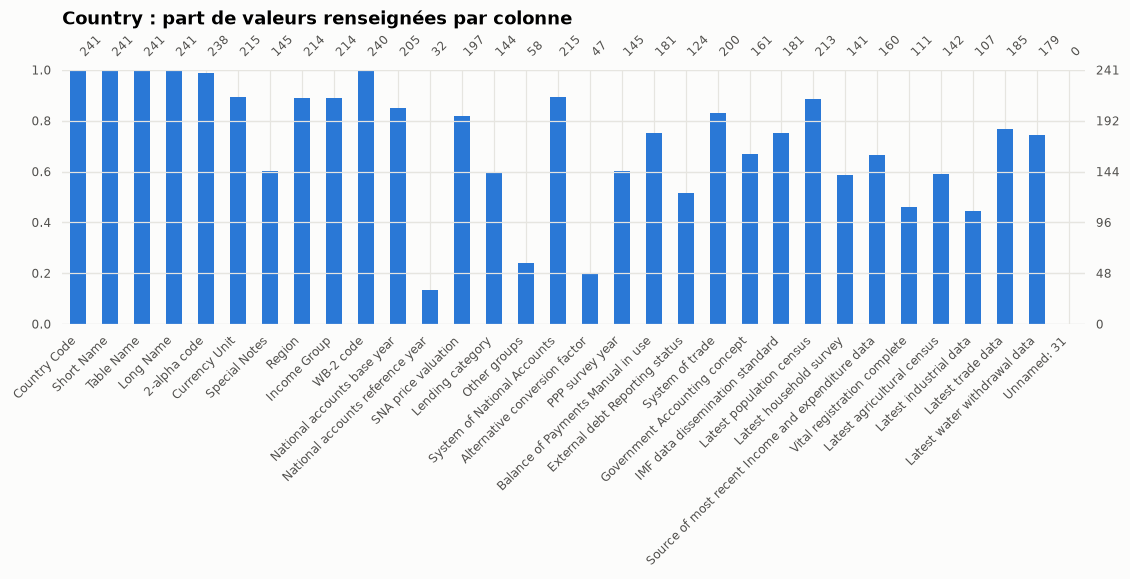

In [7]:
import missingno as msno

ax = msno.bar(country, figsize=(12, 3), fontsize=8, color=viz.BLUE)
ax.set_title("Country : part de valeurs renseignées par colonne", loc="left", fontsize=12)
plt.show()

⚠️ **Piège : supprimer trop vite.** `data.dropna()` supprimerait **toutes** les lignes, car aucune n'est remplie sur
toutes les années ! Un vide n'est pas forcément un problème : il faut d'abord savoir s'il gêne la question posée.

## 4. Les faux pays : ne jamais faire confiance à un fichier

`Country` contient des lignes « World », « Euro area », « High income »… Ce sont des **agrégats**, pas des pays.

In [8]:
country.loc[country["Region"].isna(), ["Country Code", "Short Name", "Income Group", "2-alpha code"]].head(10)

,Country Code,Short Name,Income Group,2-alpha code
5,ARB,Arab World,NaN,1A
57,EAP,East Asia & Pacific (developing only),NaN,4E
58,EAS,East Asia & Pacific (all income levels),NaN,Z4
59,ECA,Europe & Central Asia (developing only),NaN,7E
60,ECS,Europe & Central Asia (all income levels),NaN,Z7
63,EMU,Euro area,NaN,XC
68,EUU,European Union,NaN,EU
78,GIB,Gibraltar,NaN,GI
89,HIC,High income,NaN,XD
92,HPC,Heavily indebted poor countries (HIPC),NaN,XE


La règle « pas de région ⇒ faux pays » semble marcher… jusqu'à ce qu'on lise **toutes** les lignes :

In [9]:
country.loc[country["Country Code"].isin(["GIB", "NRU"]), ["Country Code", "Short Name", "Region", "2-alpha code"]]

,Country Code,Short Name,Region,2-alpha code
78,GIB,Gibraltar,NaN,GI
166,NRU,Nauru,NaN,NR


Gibraltar et Nauru sont de vrais territoires **sans** région. D'où la leçon : **une règle de nettoyage se vérifie
sur ses exceptions**. Le corrigé combine deux conditions (pas de région **et** code alpha-2 d'agrégat).

### Liste noire ou liste blanche ?

In [10]:
from edstats.cleaning import find_aggregates

faux_pays = find_aggregates(country)
vrais_pays = country[~country["Country Code"].isin(faux_pays)]  # le ~ inverse la condition : « PAS dans »

par_liste_noire = data[~data["Country Code"].isin(faux_pays)]
par_liste_blanche = data.merge(vrais_pays[["Country Code"]], on="Country Code", how="inner")
print(f"liste noire  (~isin)     : {par_liste_noire['Country Code'].nunique()} pays")
print(f"liste blanche (inner join): {par_liste_blanche['Country Code'].nunique()} pays")

liste noire  (~isin)     : 217 pays
liste blanche (inner join): 216 pays


Un pays de différence : les îles Vierges britanniques (`VGB`) sont dans `Data` mais pas dans `Country`.

| | Liste noire `~isin(faux)` | Liste blanche `merge(..., how="inner")` |
|---|---|---|
| Garde | tout ce qui n'est pas explicitement interdit | seulement ce qui est explicitement connu |
| Si un nouvel agrégat apparaît | ❌ il passe | ✅ il est bloqué |
| Si un pays manque dans `Country` | ✅ il est gardé | ❌ il est perdu (VGB) |

Aucune n'est « la bonne » dans l'absolu : il faut **savoir ce qu'on perd** avec chacune.

## 5. Le hardcoding, ou pourquoi `iloc` est dangereux pour supprimer des lignes

In [11]:
pays = country[["Country Code", "Short Name"]].head(6).reset_index(drop=True)
print("Je veux supprimer 'Arab World', qui est à la position 5 :")
print(pays.drop(index=5)["Short Name"].tolist())

pays_trie = pays.sort_values("Short Name").reset_index(drop=True)  # ... mais quelqu'un a trié le tableau avant
print("\nMême code après un tri :")
print(pays_trie.drop(index=5)["Short Name"].tolist(), " ← on a supprimé le mauvais pays !")

print("\nVersion robuste, par la valeur :")
print(pays_trie[pays_trie["Country Code"] != "ARB"]["Short Name"].tolist())

Je veux supprimer 'Arab World', qui est à la position 5 :
['Aruba', 'Afghanistan', 'Angola', 'Albania', 'Andorra']

Même code après un tri :
['Afghanistan', 'Albania', 'Andorra', 'Angola', 'Arab World']  ← on a supprimé le mauvais pays !

Version robuste, par la valeur :
['Afghanistan', 'Albania', 'Andorra', 'Angola', 'Aruba']


### ✍️ À toi de jouer

Dans `tables["Series"]`, quelle est la clé ? Vérifie-le avec `duplicated()`. Ensuite, quelles colonnes sont **entièrement** vides ?

In [12]:
# Ta réponse ici

<details>
<summary><b>💡 Voir une solution</b> (après avoir cherché !)</summary>

```python
series = tables["Series"]
print(series.duplicated(subset=["Series Code"]).sum())   # 0 : une ligne = un indicateur
series.columns[series.isna().all()].tolist()
```

`isna().all()` renvoie True pour une colonne dont **toutes** les valeurs sont manquantes.
</details>

## ✅ À retenir

1. Toujours commencer par « une ligne = … » et **le prouver** avec `duplicated(subset=clé)`.
2. Doublon exact ≠ doublon de clé ; `drop_duplicates()` ne traite que le premier.
3. Mesurer les vides **par colonne** (`isna().mean()`) avant de décider quoi supprimer.
4. Une règle de nettoyage se vérifie sur ses exceptions (Gibraltar, Nauru).
5. Filtrer **par valeur**, jamais par position : pas de hardcoding.